# Barridos con sustracción de fondo corregida

Las ventanas de resonancia se seleccionaron sobre los barridos crudos. Cada CSV
procesado guarda sus límites antes de la cabecera de datos.


In [228]:
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt

from Data import Sweep


In [229]:
def plot_amplitude_sweep(sweeps):
    """Plot the magnitude response for a collection of sweeps."""
    import numpy as np
    from matplotlib.colors import LinearSegmentedColormap

    plt.rcParams.update({
        "figure.figsize": (7.5, 5),
        "font.family": "sans-serif",
        "font.size": 20,
        "axes.labelsize": "medium",
        "axes.linewidth": 1.8,
        "axes.grid": False,
        "xtick.labelsize": "medium",
        "ytick.labelsize": "medium",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 7,
        "ytick.major.size": 7,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "lines.linewidth": 1.8,
        "legend.frameon": False,
        "figure.dpi": 100,
        "savefig.dpi": 500,
    })

    fig, ax = plt.subplots(layout="constrained")

    amplitudes = [sweep.amplitude for sweep in sweeps]
    norm = plt.Normalize(min(amplitudes), max(amplitudes))
    cmap = LinearSegmentedColormap.from_list(
        "magma",
        plt.colormaps["turbo"](np.linspace(0.0, 0.9, 256)),
    )

    for sweep in sweeps:
        ff, xx, yy = np.array(sweep.data).T
        rr = np.hypot(xx, yy)

        ax.plot(
            ff / 1e3, rr,
            color=cmap(norm(sweep.amplitude)),
            alpha=1,
        )

    ax.set_xlabel("Frecuencia excitación (kHz)")
    ax.set_ylabel("Amplitud resonador (V)")

    cbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        label="Amplitud excitación (V)",
    )

    ax.ticklabel_format(
        axis="y", style="sci", scilimits=(0, 0), useMathText=True,
    )

    return fig, ax


def plot_both_ways(sweeps):
    """Plot a small selection of sweeps with a legend instead of a colorbar."""
    import numpy as np

    plt.rcParams.update({
        "figure.figsize": (6, 5),
        "font.family": "sans-serif",
        "font.size": 20,
        "axes.labelsize": "medium",
        "axes.linewidth": 1.8,
        "axes.grid": False,
        "xtick.labelsize": "medium",
        "ytick.labelsize": "medium",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 7,
        "ytick.major.size": 7,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "lines.linewidth": 3,
        "legend.frameon": False,
        "figure.dpi": 100,
        "savefig.dpi": 500,
        "legend.fontsize": 14,
        "legend.title_fontsize": 15,
    })

    fig, ax = plt.subplots(layout="constrained")
    color = plt.colormaps["Blues"](0.90)
    linestyles = ["--", "-"]

    for index, sweep in enumerate(sweeps):
        ff, xx, yy = np.array(sweep.data).T
        rr = np.hypot(xx, yy)
        ax.plot(
            ff / 1e3, rr,
            color=color,
            linestyle=linestyles[index % len(linestyles)],
            label=f"{sweep.amplitude:g} V",
        )

    ax.set_xlabel("Frecuencia excitaci\u00f3n (kHz)")
    ax.set_ylabel("Amplitud resonador (V)")
    ax.legend(title="Amplitud excitaci\u00f3n (V)")
    ax.ticklabel_format(
        axis="y", style="sci", scilimits=(0, 0), useMathText=True,
    )

    return fig, ax


def plot_high_voltage_sweeps(sweeps, directions):
    """Plot high-voltage sweeps with one color per excitation voltage."""
    import numpy as np

    plt.rcParams.update({
        "figure.figsize": (7.5, 5),
        "font.family": "sans-serif",
        "font.size": 20,
        "axes.labelsize": "medium",
        "axes.linewidth": 1.8,
        "axes.grid": False,
        "xtick.labelsize": "medium",
        "ytick.labelsize": "medium",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 7,
        "ytick.major.size": 7,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "lines.linewidth": 2,
        "legend.frameon": False,
        "legend.fontsize": 14,
        "legend.title_fontsize": 15,
        "figure.dpi": 100,
        "savefig.dpi": 500,
    })

    fig, ax = plt.subplots(layout="constrained")
    colors = plt.colormaps["Dark2"].colors
    amplitudes = sorted({sweep.amplitude for sweep in sweeps})
    color_by_amplitude = {
        amplitude: colors[index % len(colors)]
        for index, amplitude in enumerate(amplitudes)
    }
    labeled_amplitudes = set()

    for sweep, direction in zip(sweeps, directions):
        ff, xx, yy = np.array(sweep.data).T
        rr = np.hypot(xx, yy)
        label = (
            f"{sweep.amplitude:g} V"
            if sweep.amplitude not in labeled_amplitudes
            else "_nolegend_"
        )
        labeled_amplitudes.add(sweep.amplitude)
        ax.plot(
            ff / 1e3, rr,
            color=color_by_amplitude[sweep.amplitude],
            linestyle="--" if direction == "backward" else "-",
            label=label,
        )

    ax.set_xlabel("Frecuencia excitaci\u00f3n (kHz)")
    ax.set_ylabel("Amplitud resonador (V)")
    ax.legend(title="Amplitud excitaci\u00f3n (V)")
    ax.ticklabel_format(
        axis="y", style="sci", scilimits=(0, 0), useMathText=True,
    )

    return fig, ax



def plot_high_voltage_separated(sweeps, excitation_labels):
    """Plot high-voltage sweeps on separate y axes with a shared x axis."""
    import numpy as np
    from matplotlib.ticker import MaxNLocator

    if len(sweeps) != len(excitation_labels):
        raise ValueError(
            "Debe haber una etiqueta de excitación por cada barrido."
        )

    figure_size = (7, 9)
    font_size = 20
    blue = plt.colormaps["Blues"](0.75)

    fig, axes = plt.subplots(
        nrows=len(sweeps),
        ncols=1,
        sharex=True,
        figsize=figure_size,
        layout="constrained",
    )
    axes = np.atleast_1d(axes)

    for ax, sweep, excitation_label in zip(
        axes,
        sweeps,
        excitation_labels,
    ):
        frequency, x_signal, y_signal = np.array(sweep.data).T
        amplitude = np.hypot(x_signal, y_signal)
        ax.plot(frequency / 1e3, amplitude, color=blue)
        ax.set_ylim(
            bottom=0,
            top=1.28 * np.max(amplitude),
        )
        ax.tick_params(axis="both", labelsize=font_size)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.ticklabel_format(
            axis="y", style="sci", scilimits=(0, 0), useMathText=True,
        )
        ax.yaxis.get_offset_text().set_fontsize(font_size)
        ax.text(
            0.97,
            0.94,
            f"Excitación: {excitation_label}",
            transform=ax.transAxes,
            fontsize=font_size,
            ha="right",
            va="top",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.85,
                "pad": 2,
            },
        )
        ax.grid(False)

    fig.supylabel(
        "Amplitud resonador (V)",
        fontsize=font_size,
    )
    axes[-1].set_xlabel(
        "Frecuencia excitación (kHz)",
        fontsize=font_size,
        labelpad=8,
    )
    fig.set_constrained_layout_pads(
        w_pad=0.08,
        h_pad=0.08,
        hspace=0.05,
    )

    return fig, axes


In [230]:
# Corrección de barridos


windows = {
    # "26-10-1507": (64700, 66600),
    # "26-10-1522": (64750, 65300),
    "26-10-1644": (64550, 64750),
    "26-10-1651": (64400, 64800),
    "26-10-1657": (64400, 64800),
    "26-10-1704": (64400, 64950),
    "26-10-1711": (64350, 65250),
    "26-10-1717": (64300, 65550),
    "26-10-1724": (64250, 65650),
    "26-10-1730": (64250, 65900),
    "26-10-1737": (64200, 66100),
    "26-10-1744": (64200, 66450),
    "26-10-1750": (64200, 66800),
    "26-10-1757": (64150, 67200),
}
source_folder = Path("Mediciones/Barrido_Amplitudes")
output_folder = source_folder / "mediciones_sin_fondo_corregida"
raw_files = sorted(source_folder.glob("*.csv"))

# Desde el barrido 26-10-1812 la ventana es la misma para todos.
for file in raw_files[12:]:
    windows[file.stem] = (64150, 67450)

output_folder.mkdir(parents=True, exist_ok=True)

for file in raw_files:
    sweep = Sweep(file)
    corrected = sweep.subtract_background(windows[file.stem])
    corrected.save(output_folder / f"{file.stem}_SF.csv")

print(f"Se generaron {len(raw_files)} barridos corregidos")


Se generaron 84 barridos corregidos


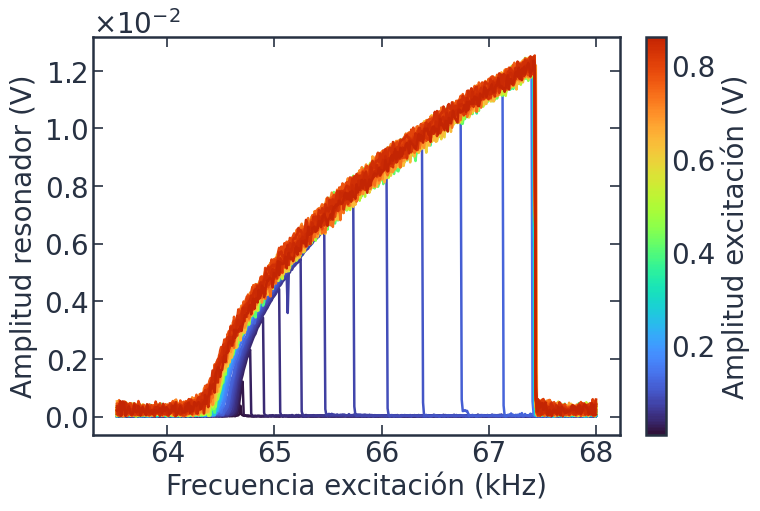

In [231]:
%matplotlib inline
sweeps = [Sweep(file) for file in sorted(output_folder.glob("*_SF.csv"))]

fig, ax = plot_amplitude_sweep(sweeps)

fig.savefig(
    r"C:\Main\Drive\Facultad\Materias\Experimental III\Figuras\barridos_amplitud.png",
)

import numpy as np
from matplotlib.colors import LinearSegmentedColormap

amplitudes = np.array([sweep.amplitude for sweep in sweeps])
cutoff_frequencies = np.array([
    frequency[np.argmax(np.hypot(x_signal, y_signal))]
    for frequency, x_signal, y_signal in (np.array(sweep.data).T for sweep in sweeps)
])
norm = plt.Normalize(amplitudes.min(), amplitudes.max())
cmap = LinearSegmentedColormap.from_list(
    "turbo_truncated", plt.colormaps["turbo"](np.linspace(0.0, 0.9, 256)),
)

fig_cutoff, ax_cutoff = plt.subplots(layout="constrained")
ax_cutoff.scatter(amplitudes, cutoff_frequencies / 1e3, c=cmap(norm(amplitudes)), s=45)
ax_cutoff.set(
    xlabel="Amplitud excitación (V)",
    ylabel="Frecuencia de corte (kHz)",
)


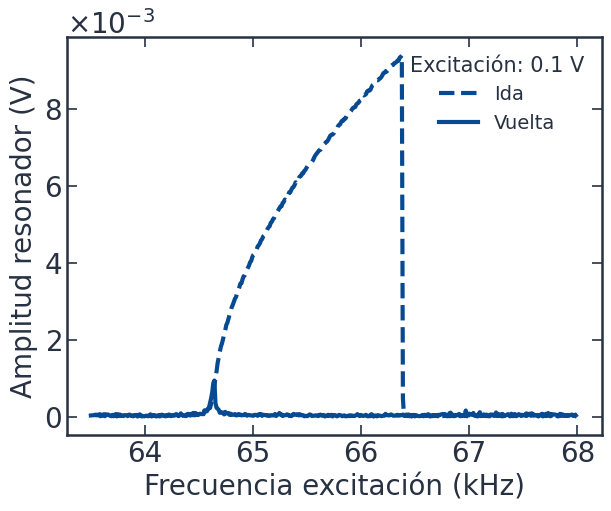

In [232]:
%matplotlib inline
ida_y_vuelta_folder = Path(r"C:\Main\Repos\MEMS\Mediciones\Ida_y_Vuelta")
ida_y_vuelta_file = next(ida_y_vuelta_folder.glob("*.csv"))
ida_y_vuelta_sweep = Sweep(ida_y_vuelta_file)
forward_window = (64500, 66400)
backward_window = (64500, 66400)
ida_y_vuelta_corrected = ida_y_vuelta_sweep.subtract_background_bidirectional(
    forward_window, backward_window
)
fig_ida_y_vuelta, ax_ida_y_vuelta = plot_both_ways(ida_y_vuelta_corrected)
ax_ida_y_vuelta.lines[0].set_label("Ida")
ax_ida_y_vuelta.lines[1].set_label("Vuelta")
ax_ida_y_vuelta.legend(
    title=f"Excitaci\u00f3n: {ida_y_vuelta_sweep.amplitude:g} V"
)
fig_ida_y_vuelta.savefig(
    ida_y_vuelta_folder / "ida_y_vuelta_corregida.png",
    dpi=500,
    bbox_inches="tight",
)
plt.show()


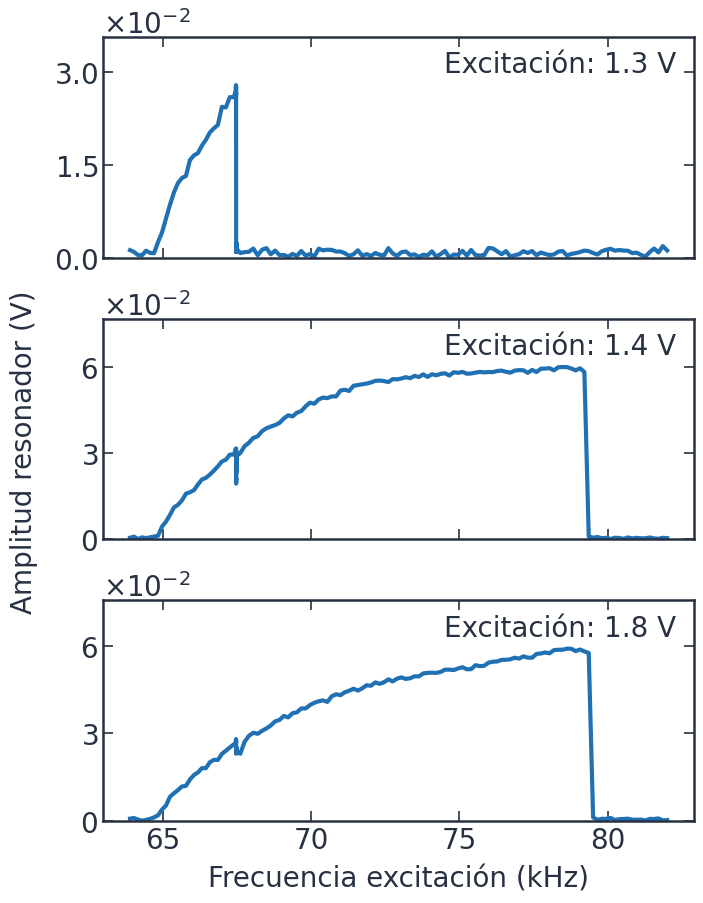

In [233]:
%matplotlib inline
from importlib import reload
from pathlib import Path

import Data
import numpy as np

Data = reload(Data)
Sweep = Data.Sweep

alto_voltaje_folder = Path(
    r"C:\Main\Repos\MEMS\Mediciones\alto voltaje"
)
correction_parameters = {
    "1.3v_1": ((64500, 67500), 4),
    "1.4v_1": ((64500, 79400), 4),
    "1.8v_1": ((64500, 79400), 4),
}
corrected_sweeps = []

for folder, (resonance_window, degree) in correction_parameters.items():
    forward_parts = []

    for file in sorted((alto_voltaje_folder / folder).glob("*.csv")):
        sweep = Sweep(file)
        frequencies = np.array(
            [frequency for frequency, _, _ in sweep.data]
        )

        if np.any(np.diff(frequencies) < 0):
            sweep, _ = sweep.split_bidirectional()

        forward_parts.append(sweep)

    forward = Sweep.stitch(forward_parts)
    corrected_sweeps.append(
        forward.subtract_background(resonance_window, degree=degree)
    )

fig_separated, axes_separated = plot_high_voltage_separated(
    corrected_sweeps,
    ("1.3 V", "1.4 V", "1.8 V"),
)
fig_separated.savefig(
    alto_voltaje_folder / "alto_voltaje_corregido_ejes_separados.png",
    dpi=500,
    bbox_inches="tight",
)
plt.show()


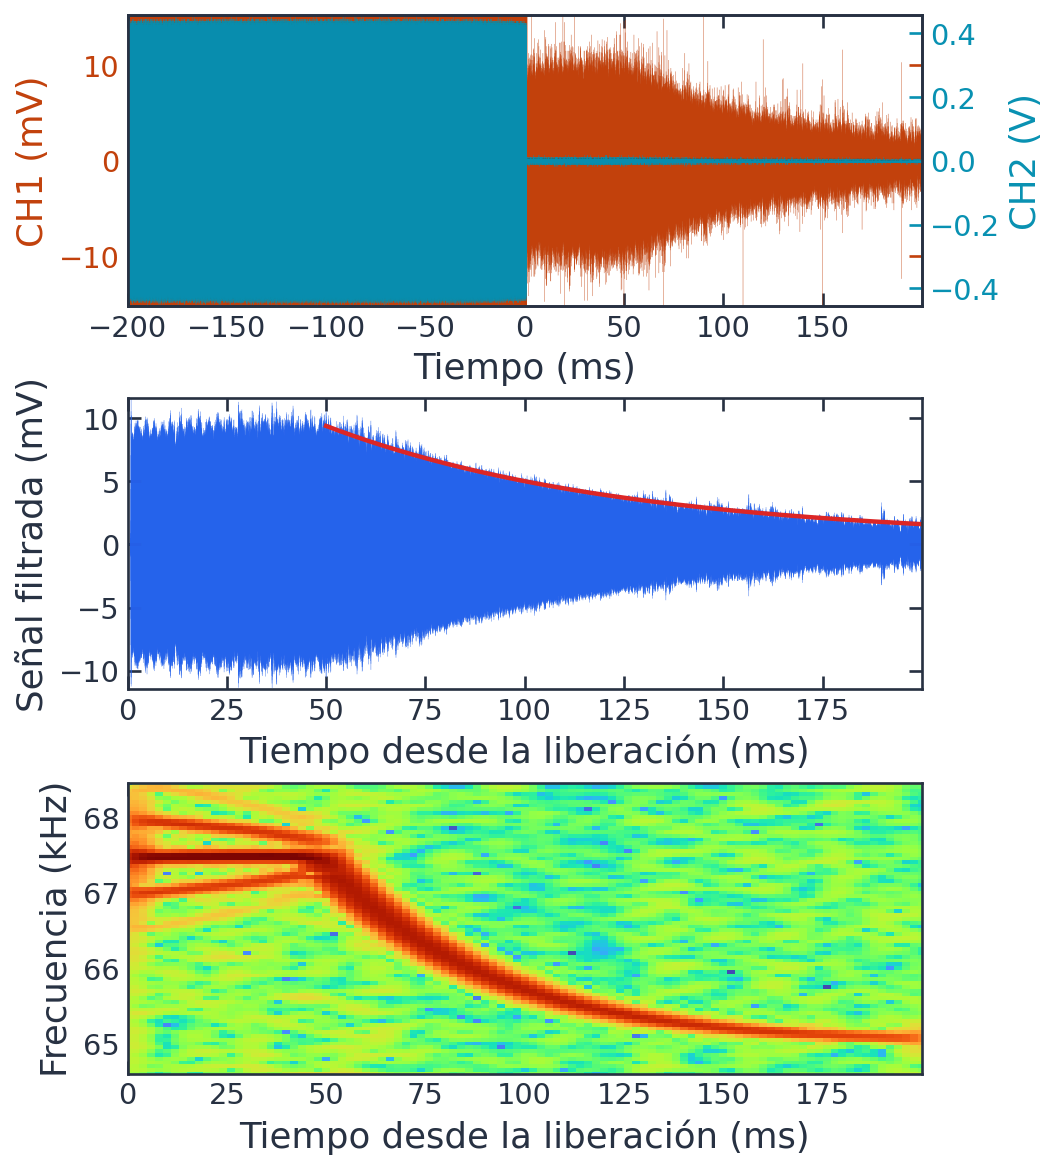

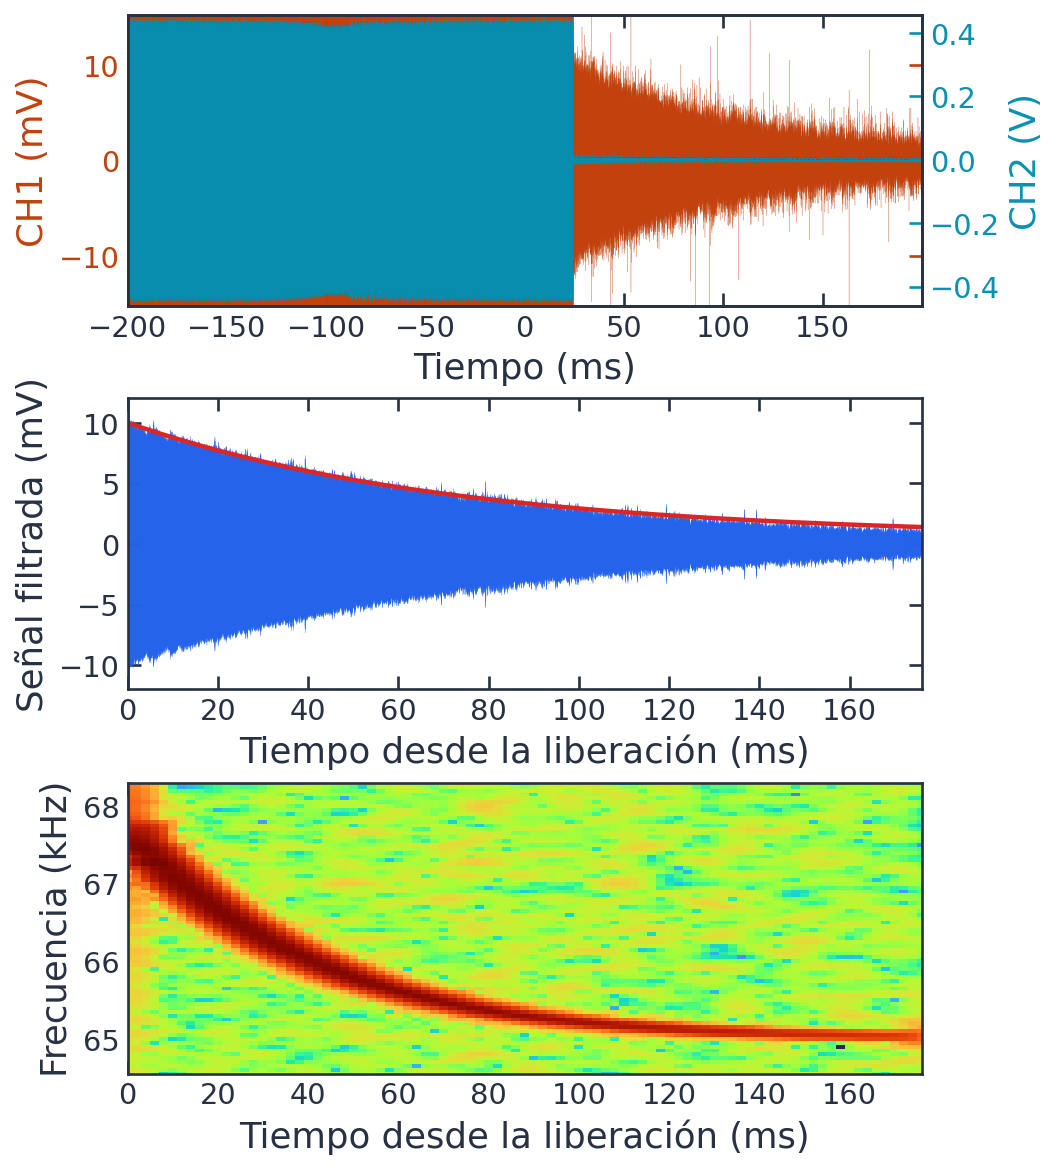

In [234]:
from pathlib import Path
from Data import Ringdown
ringdown_1625 = Ringdown(Path(r"C:\Main\Repos\MEMS\Mediciones\Ringdowns del 2-11\ringdown-02-11-1625.csv"))
ringdown_1637 = Ringdown(Path(r"C:\Main\Repos\MEMS\Mediciones\Ringdowns del 2-11\ringdown-02-11-1637.csv"))
for ringdown, release_time, decay_start_time in ((ringdown_1625, 0, 0.05), (ringdown_1637, 0.024, 0)):
    ringdown.reconstruct(release_time).analyze((60e3, 75e3), decay_start_time=decay_start_time).plot();


Frecuencia del modo pandeo: 65.0764 kHz
Factor de calidad: 21129


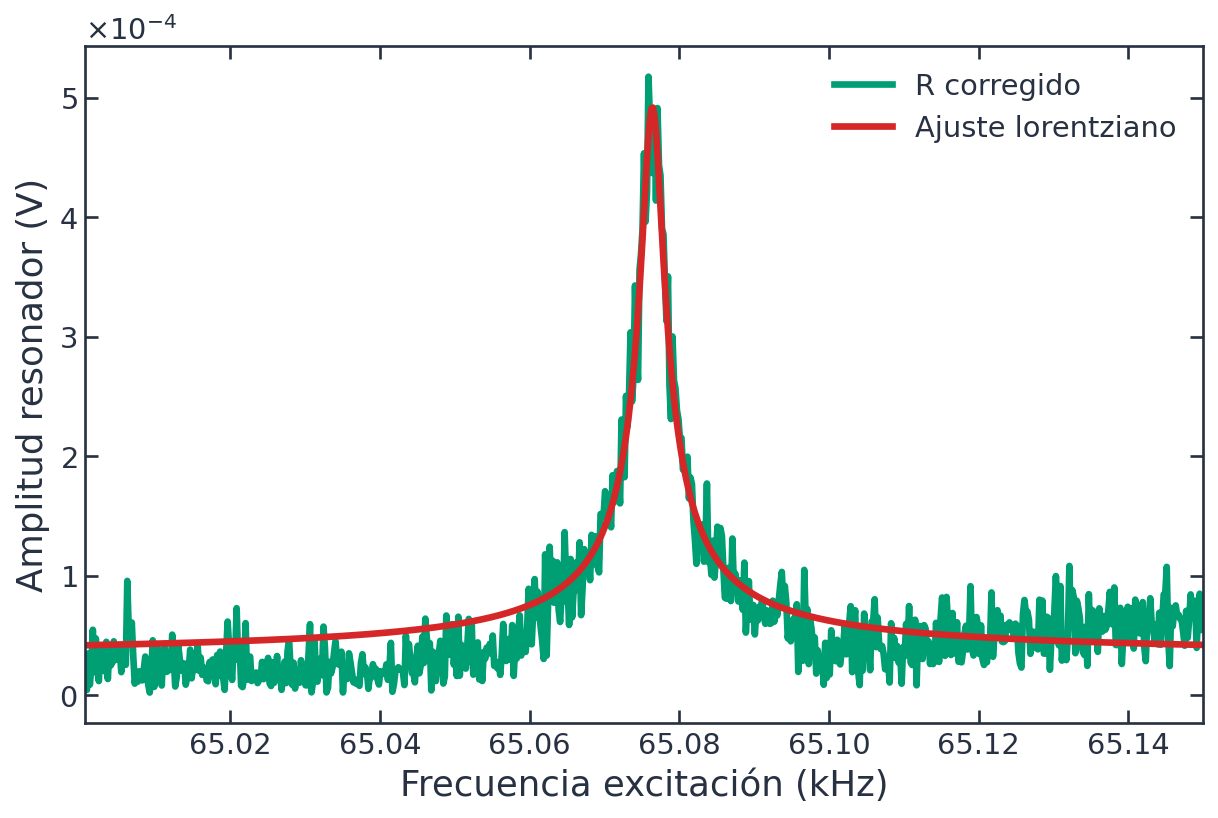

In [239]:
import numpy as np
from scipy.optimize import curve_fit
sweep_5111825 = Sweep(Path(r"C:\Main\Repos\MEMS\05-11-1825.csv"))
window_5111825 = (65060, 65150)
corrected_5111825 = sweep_5111825.subtract_background(window_5111825)
frequency, x_signal, y_signal = np.array(corrected_5111825.data).T
amplitude = np.hypot(x_signal, y_signal)
plot_mask = frequency <= window_5111825[1]
fit_mask = (frequency >= window_5111825[0]) & (frequency <= window_5111825[1])
lorentzian = lambda f, offset, height, center, half_width: offset + height / np.sqrt(1 + ((f - center) / half_width) ** 2)
parameters, _ = curve_fit(lorentzian, frequency[fit_mask], amplitude[fit_mask], p0=(np.median(amplitude[~fit_mask]), amplitude[fit_mask].max(), frequency[fit_mask][amplitude[fit_mask].argmax()], 3), bounds=([-np.inf, 0, window_5111825[0], 0], [np.inf, np.inf, window_5111825[1], np.inf]))
fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
ax.plot(frequency[plot_mask] / 1e3, amplitude[plot_mask], color="#009E73", label="R corregido")
ax.plot(frequency[plot_mask] / 1e3, lorentzian(frequency[plot_mask], *parameters), color="#D62728", label="Ajuste lorentziano")
ax.set(xlabel="Frecuencia excitación (kHz)", ylabel="Amplitud resonador (V)", xlim=(frequency[plot_mask].min() / 1e3, frequency[plot_mask].max() / 1e3))
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True); ax.legend();
print(f"Frecuencia del modo pandeo: {parameters[2] / 1e3:.4f} kHz")
print(f"Factor de calidad: {parameters[2] / (2 * parameters[3]):.0f}")


In [236]:
q_sweep = parameters[2] / (2 * parameters[3])
q_ringdown = {"16:25": np.pi * parameters[2] / ringdown_1625.damping, "16:37": np.pi * parameters[2] / ringdown_1637.damping}
peak_frequencies = [np.array(sweep.data).T[0][np.argmax(np.hypot(*np.array(sweep.data).T[1:]))] for sweep in sweeps]
mode_1_ri_frequency = np.median(peak_frequencies)
mode_3_frequency = 3 * mode_1_ri_frequency
print(f"Q del barrido: {q_sweep:.0f}")
print("Q de ringdown:", {name: f"{value:.0f}" for name, value in q_ringdown.items()})
print(f"Frecuencia modo 1 lineal: {parameters[2] / 1e3:.3f} kHz")
print(f"Frecuencia modo 1 RI: {mode_1_ri_frequency / 1e3:.3f} kHz")
print(f"Frecuencia modo 3: {mode_3_frequency / 1e3:.3f} kHz")


Q del barrido: 21129
Q de ringdown: {'16:25': '15349', '16:37': '14751'}
